# 多层感知机：非线性表示、反向传播与分类实验

## 实验摘要

本次固定运行选择第9轮，测试准确率为88.11%，测试交叉熵为0.3416。测试集中最频繁的单向混淆是T-shirt/top被预测为Shirt，共121张；这反映了本次模型与划分中的错误集中位置，不等于类别之间的普遍关系。

## 内容范围与实验设计

本项目依据《动手学深度学习》中文版第4.1—4.3及4.7—4.8的相关基础：隐藏层、激活函数、实现、反向传播与初始化，将数学表达、张量实现与可复现实验组织在同一份技术笔记中。主体按教材概念顺序展开，补充实现一致性检查、独立验证集和错误分析。

实验使用Fashion-MNIST官方数据：原训练集60000张中分层留出10000张作为验证集，50000张用于参数训练；官方10000张测试图像仅用于最终评估。图像为28×28灰度图，共10类。像素除以255，无数据增强。

## 环境与复现

安装根目录requirements.txt，重启内核并运行全部单元格。首次运行需下载约30MB数据并核验MD5，缓存不提交至仓库。训练默认CPU、固定随机种子；依赖版本见requirements-lock.txt。三个项目各自独立运行。

In [1]:
NAME='mlp'

from pathlib import Path
import copy, json, platform
import numpy as np
import torch
from torch import nn
from torch.nn import functional as F
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix
from IPython.display import display, Markdown
# 无论从项目根目录还是 notebooks 目录启动，都定位到本项目。
ROOT = Path.cwd()
if ROOT.name == 'notebooks': ROOT = ROOT.parent
assert (ROOT / 'notebooks').is_dir(), '请从 项目根目录或其 notebooks 目录运行'
(ROOT / 'figures').mkdir(exist_ok=True)
(ROOT / 'results').mkdir(exist_ok=True)
torch.set_num_threads(4)
torch.use_deterministic_algorithms(True)
torch.manual_seed(42)
np.random.seed(42)
plt.rcParams.update({'figure.dpi': 120, 'font.size': 11, 'axes.spines.top': False,
                     'axes.spines.right': False, 'savefig.bbox': 'tight'})
def savefig(name):
    plt.savefig(ROOT / 'figures' / (name + '.png'), dpi=150)
    plt.show()
print('Python', platform.python_version(), '| PyTorch', torch.__version__)

Python 3.13.9 | PyTorch 2.14.1+cpu


## 1. 隐藏层与非线性表达
对行向量，隐藏层 $H=\operatorname{ReLU}(XW_1+b_1)$，输出分数 $Z=HW_2+b_2$。若删除ReLU，代入可得 $Z=X(W_1W_2)+(b_1W_2+b_2)$，仍是一个仿射映射。增加线性层数量不会自动获得非线性表达能力。

ReLU逐元素取 $\max(0,x)$，使空间分成不同的线性区域。下面用异或XOR说明：单条直线不能分开两组对角点；构造 $h_1=\operatorname{ReLU}(x_1-x_2)$、$h_2=\operatorname{ReLU}(x_2-x_1)$，则 $h_1+h_2=|x_1-x_2|$ 可以在这四个点上分开标签。该构造用于验证表达能力，未涉及参数训练。

## 2. 激活函数、反向传播与初始化
对单隐藏层网络，记 $A=XW_1+b_1$、$H=\phi(A)$、$Z=HW_2+b_2$，平均交叉熵对输出的梯度为 $G=(P-Y)/n$。链式法则给出
$$\nabla_{W_2}L=H^TG,\quad \nabla_{b_2}L=\sum_iG_i,$$
$$D=(GW_2^T)\odot\phi'(A),\quad\nabla_{W_1}L=X^TD,\quad\nabla_{b_1}L=\sum_iD_i.$$
ReLU在正半轴导数为1、负半轴为0；原点采用框架约定的子梯度。Sigmoid导数为 $s(1-s)$，Tanh导数为 $1-t^2$，饱和区域的导数接近0。梯度需要经过各层局部导数，因而激活函数与权重尺度共同影响优化。

不同隐藏单元若具有完全相同的初始化，会获得相同响应和梯度，难以学习不同表示。本实验用小幅随机正态权重打破对称，偏置为0；这不意味着此初始化对任意深度都适用。

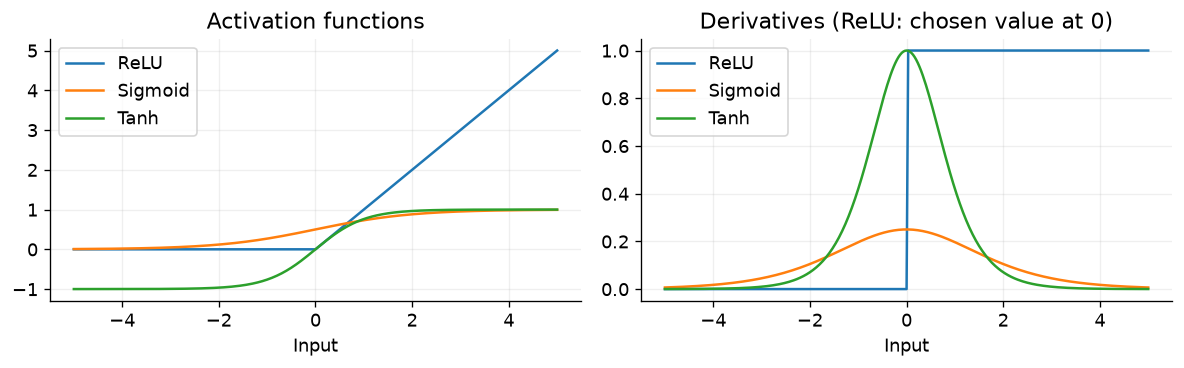

In [2]:
t=torch.linspace(-5,5,301)
fig,axes=plt.subplots(1,2,figsize=(10,3.2))
for title,values,grad in [('ReLU',F.relu(t),(t>0).float()),('Sigmoid',t.sigmoid(),t.sigmoid()*(1-t.sigmoid())),('Tanh',t.tanh(),1-t.tanh()**2)]:
    axes[0].plot(t,values,label=title);axes[1].plot(t,grad,label=title)
for ax,title in zip(axes,['Activation functions','Derivatives (ReLU: chosen value at 0)']):ax.set(xlabel='Input',title=title);ax.legend();ax.grid(alpha=.2)
plt.tight_layout();savefig('mlp_activations')

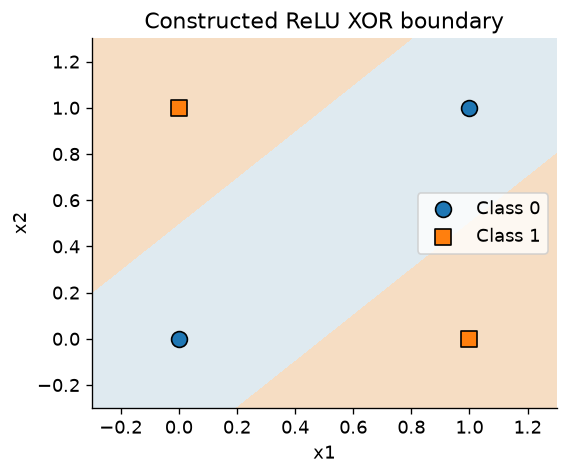

In [3]:
x=torch.tensor([[0.,0.],[0.,1.],[1.,0.],[1.,1.]])
target=torch.tensor([0,1,1,0])
W1=torch.tensor([[1.,-1.],[-1.,1.]])
h=F.relu(x@W1); score=h.sum(1)
assert torch.equal((score>.5).long(),target)
a=torch.randn(2,5); b=torch.randn(5); c=torch.randn(5,2); d=torch.randn(2)
torch.testing.assert_close((x@a+b)@c+d,x@(a@c)+(b@c+d))
grid=np.linspace(-.3,1.3,150); xx,yy=np.meshgrid(grid,grid)
fig,ax=plt.subplots(figsize=(5,4))
ax.contourf(xx,yy,(np.abs(xx-yy)>.5).astype(int),levels=[-.5,.5,1.5],colors=['#DFEAF0','#F6DDC3'])
for label,marker in [(0,'o'),(1,'s')]:
    points=x[target==label];ax.scatter(points[:,0],points[:,1],marker=marker,s=90,label=f'Class {label}',edgecolor='black')
ax.set(xlabel='x1',ylabel='x2',title='Constructed ReLU XOR boundary');ax.legend()
savefig('mlp_xor')

## 3. Fashion-MNIST分类实验
采用784→256→10的单隐藏层MLP，隐藏层使用ReLU，输出层保留原始分数。参数量203530。各层维度与参数量在代码中显式核对。

训练 / 验证 / 测试: 50000 10000 10000


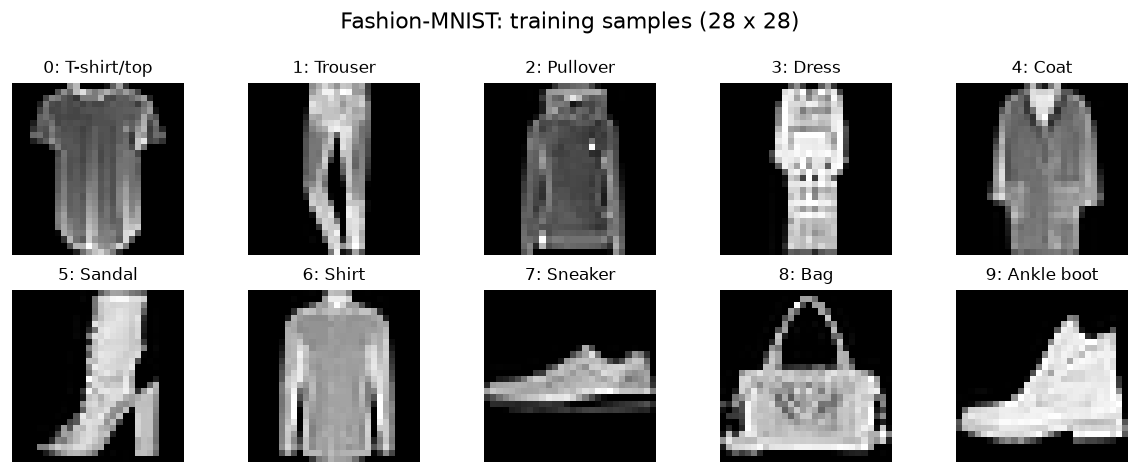

In [4]:

import sys, os
sys.path.insert(0,str(ROOT/'src'))
from fashion_data import load_fashion, CLASSES
raw_x, raw_y, raw_test_x, raw_test_y = load_fashion(os.environ.get('FASHION_MNIST_CACHE',ROOT/'data'))
assert len(raw_y)==60000 and len(raw_test_y)==10000
# 固定像素缩放，无全数据统计估计；官方测试集保持独立。
X=torch.tensor(np.concatenate([raw_x,raw_test_x]),dtype=torch.float32)/255.0
y=torch.tensor(np.concatenate([raw_y,raw_test_y]),dtype=torch.long)
train_idx,val_idx=train_test_split(np.arange(60000),test_size=10000,stratify=raw_y,random_state=41)
test_idx=np.arange(60000,70000)
assert not(set(train_idx)&set(val_idx) or set(train_idx)&set(test_idx) or set(val_idx)&set(test_idx))
assert len(train_idx)+len(val_idx)+len(test_idx)==len(y)
print('训练 / 验证 / 测试:',len(train_idx),len(val_idx),len(test_idx))
fig,axes=plt.subplots(2,5,figsize=(10,4))
for label,ax in enumerate(axes.flat):
    idx=next(i for i in train_idx if y[i].item()==label)
    ax.imshow(X[idx,0],cmap='gray',vmin=0,vmax=1);ax.set_title(f'{label}: {CLASSES[label]}',fontsize=10);ax.axis('off')
fig.suptitle('Fashion-MNIST: training samples (28 x 28)');plt.tight_layout();savefig(NAME+'_samples')


In [5]:
torch.manual_seed(42)
model=nn.Sequential(nn.Flatten(),nn.Linear(784,256),nn.ReLU(),nn.Linear(256,10))
for layer in model:
    if isinstance(layer,nn.Linear): nn.init.normal_(layer.weight,mean=0,std=0.01);nn.init.zeros_(layer.bias)
assert sum(p.numel() for p in model.parameters())==203530
with torch.no_grad():
    probe=X[train_idx[:2]]
    for layer in model: probe=layer(probe);print(type(layer).__name__,tuple(probe.shape))

Flatten (2, 784)
Linear (2, 256)
ReLU (2, 256)
Linear (2, 10)


### 显式张量实现与模块实现的一致性
在相同参数、输入和损失下比较两种表达的输出与梯度，避免初始化差异掩盖实现错误。训练主循环采用模块形式，计算规则与显式实现一致。

In [6]:
# 使用模块当前参数构造显式矩阵计算，并同时核对前向结果与参数梯度。
batch=X[train_idx[:8]].flatten(1); labels=y[train_idx[:8]]
model.zero_grad()
w1=model[1].weight.detach().T.clone().requires_grad_(); b1=model[1].bias.detach().clone().requires_grad_()
w2=model[3].weight.detach().T.clone().requires_grad_(); b2=model[3].bias.detach().clone().requires_grad_()
a=batch@w1+b1; hidden=torch.clamp(a,min=0); explicit=hidden@w2+b2
F.cross_entropy(explicit,labels).backward()
F.cross_entropy(model(X[train_idx[:8]]),labels).backward()
torch.testing.assert_close(explicit,model(X[train_idx[:8]]))
for direct,framework in [(w1.grad.T,model[1].weight.grad),(b1.grad,model[1].bias.grad),
                          (w2.grad.T,model[3].weight.grad),(b2.grad,model[3].bias.grad)]:torch.testing.assert_close(direct,framework)
# 手推链式法则与自动微分独立核对；随机预激活不处于ReLU不可导点。
g=(explicit.detach().softmax(1)-F.one_hot(labels,10))/len(labels)
dh=(g@w2.detach().T)*(a.detach()>0)
torch.testing.assert_close(w2.grad,hidden.detach().T@g)
torch.testing.assert_close(w1.grad,batch.T@dh)
model.zero_grad()
print('显式实现与模块实现：前向输出及参数梯度核对通过。')

显式实现与模块实现：前向输出及参数梯度核对通过。


epoch 01 | train CE 0.4648 | validation CE 0.4785 | validation accuracy 81.97%


epoch 02 | train CE 0.3770 | validation CE 0.4033 | validation accuracy 85.28%


epoch 03 | train CE 0.3276 | validation CE 0.3651 | validation accuracy 86.90%


epoch 04 | train CE 0.2966 | validation CE 0.3410 | validation accuracy 87.90%


epoch 05 | train CE 0.2823 | validation CE 0.3331 | validation accuracy 87.78%


epoch 06 | train CE 0.2614 | validation CE 0.3208 | validation accuracy 88.55%


epoch 07 | train CE 0.2817 | validation CE 0.3528 | validation accuracy 87.35%


epoch 08 | train CE 0.2526 | validation CE 0.3261 | validation accuracy 88.49%


epoch 09 | train CE 0.2350 | validation CE 0.3162 | validation accuracy 88.71%


epoch 10 | train CE 0.2361 | validation CE 0.3270 | validation accuracy 88.23%


由验证集交叉熵选择的轮次: 9


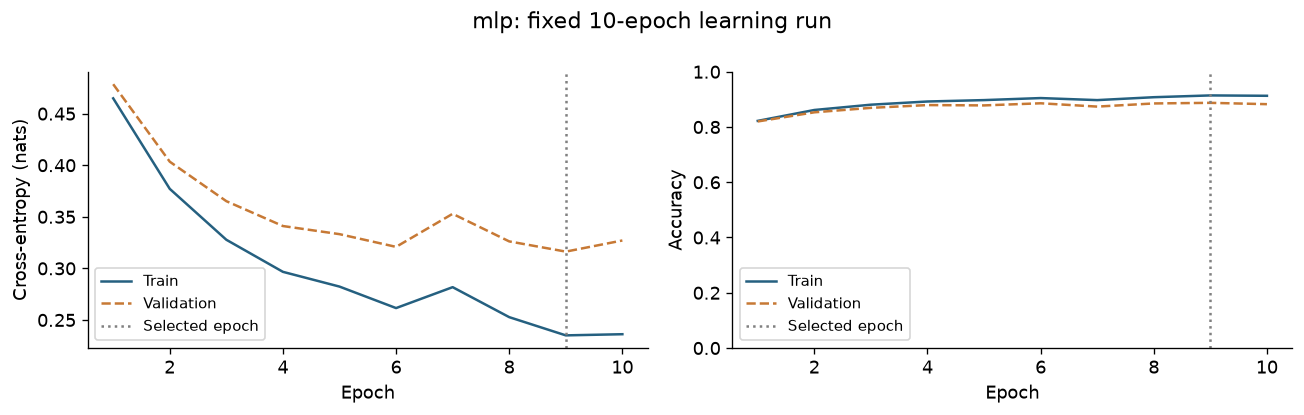

In [7]:
# 所有模型使用固定 10 轮、Adam、相同批次顺序；不根据测试结果调参。
EPOCHS, LR, BATCH = 10, 0.003, 256
optimizer = torch.optim.Adam(model.parameters(), lr=LR)
order_rng = torch.Generator().manual_seed(44)
history = []
best_val, best_state, best_epoch = float('inf'), None, None
@torch.no_grad()
def evaluate(net, idx):
    net.eval()
    loss_sum, correct = 0., 0
    for batch in torch.tensor(idx).split(512):
        logits = net(X[batch])
        loss_sum += F.cross_entropy(logits, y[batch], reduction='sum').item()
        correct += (logits.argmax(1)==y[batch]).sum().item()
    return loss_sum/len(idx), correct/len(idx)
for epoch in range(1, EPOCHS+1):
    model.train()
    order = torch.tensor(train_idx)[torch.randperm(len(train_idx), generator=order_rng)]
    for batch in order.split(BATCH):
        optimizer.zero_grad()
        logits = model(X[batch])
        assert logits.shape == (len(batch), 10)
        loss = F.cross_entropy(logits, y[batch])  # 直接传入 logits，不先 softmax
        assert torch.isfinite(loss)
        loss.backward()
        optimizer.step()
    train_loss, train_acc = evaluate(model, train_idx)
    val_loss, val_acc = evaluate(model, val_idx)
    history.append([epoch, train_loss, val_loss, train_acc, val_acc])
    print(f"epoch {epoch:02d} | train CE {train_loss:.4f} | validation CE {val_loss:.4f} | validation accuracy {val_acc:.2%}", flush=True)
    if val_loss < best_val:
        best_val, best_epoch = val_loss, epoch
        best_state = copy.deepcopy(model.state_dict())
model.load_state_dict(best_state)
print('由验证集交叉熵选择的轮次:', best_epoch)
fig, axes = plt.subplots(1,2,figsize=(11,3.5))
h = np.array(history)
for ax, cols, ylabel in [(axes[0],(1,2),'Cross-entropy (nats)'),(axes[1],(3,4),'Accuracy')]:
    ax.plot(h[:,0],h[:,cols[0]],label='Train',color='#256080')
    ax.plot(h[:,0],h[:,cols[1]],label='Validation',color='#C77935',linestyle='--')
    ax.axvline(best_epoch,color='gray',linestyle=':',label='Selected epoch')
    ax.set(xlabel='Epoch',ylabel=ylabel); ax.legend(fontsize=9)
axes[1].set_ylim(0,1)
fig.suptitle(NAME + ': fixed 10-epoch learning run')
plt.tight_layout(); savefig(NAME + '_learning')

## 4. 测试结果与错误分析

测试准确率 **88.11%**；交叉熵 **0.3416**；多数类基线 **10.00%**；参数量 **203,530**。

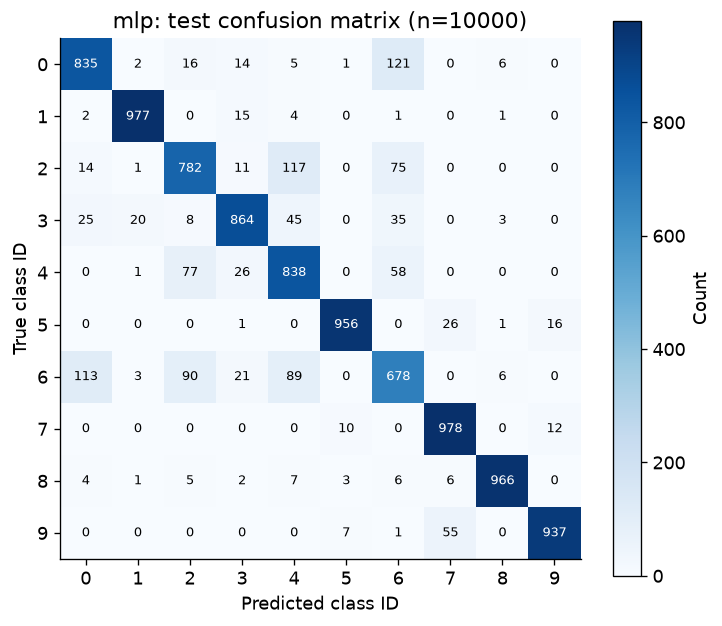

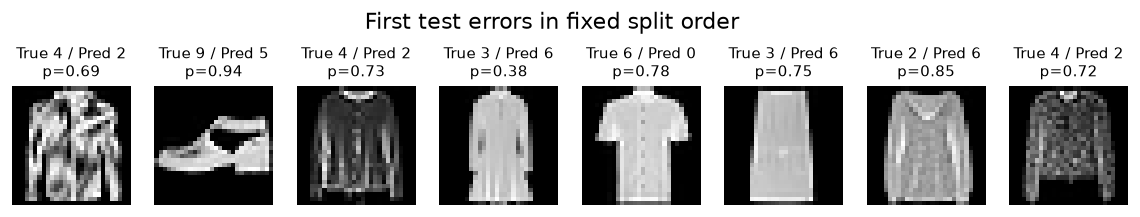

In [8]:
# 训练和选择均已完成，现在评估一次测试集。
test_loss, test_acc = evaluate(model, test_idx)
model.eval()
with torch.no_grad():
    test_logits = torch.cat([model(X[b]) for b in torch.tensor(test_idx).split(512)]); probs = test_logits.softmax(1); pred = probs.argmax(1)
majority = torch.bincount(y[train_idx], minlength=10).argmax()
baseline = (y[test_idx]==majority).float().mean().item()
result = dict(model=NAME, dataset='Fashion-MNIST', train_n=len(train_idx), val_n=len(val_idx),
              test_n=len(test_idx), split_seeds=[41], model_seed=42, batch_seed=44,
              epochs=EPOCHS, learning_rate=LR, batch_size=BATCH, selected_epoch=best_epoch,
              parameter_count=sum(p.numel() for p in model.parameters()),
              test_cross_entropy=test_loss, test_accuracy=test_acc, majority_accuracy=baseline,
              torch_version=torch.__version__, python_version=platform.python_version())
(ROOT/'results'/f'{NAME}.json').write_text(json.dumps(result,indent=2),encoding='utf-8')
np.savez(ROOT/'results'/f'{NAME}_run.npz', train_indices=train_idx, validation_indices=val_idx,
         test_indices=test_idx, history=np.array(history), test_probabilities=probs.numpy(),
         test_labels=y[test_idx].numpy())
display(Markdown(f'测试准确率 **{test_acc:.2%}**；交叉熵 **{test_loss:.4f}**；多数类基线 **{baseline:.2%}**；参数量 **{result["parameter_count"]:,}**。'))
cm = confusion_matrix(y[test_idx],pred,labels=np.arange(10))
assert cm.sum() == len(test_idx)
fig,ax=plt.subplots(figsize=(7,6)); im=ax.imshow(cm,cmap='Blues',vmin=0)
for i in range(10):
    for j in range(10):
        ax.text(j,i,str(cm[i,j]),ha='center',va='center',fontsize=8,color='white' if cm[i,j]>cm.max()/2 else 'black')
ax.set(xticks=range(10),yticks=range(10),xlabel='Predicted class ID',ylabel='True class ID',title=f'{NAME}: test confusion matrix (n={len(test_idx)})')
fig.colorbar(im,ax=ax,label='Count'); savefig(NAME+'_confusion')
wrong=torch.where(pred != y[test_idx])[0][:8]
if len(wrong):
    fig,axes=plt.subplots(1,len(wrong),figsize=(max(3,len(wrong)*1.5),2.3),squeeze=False)
    for ax,j in zip(axes[0],wrong):
        ax.imshow(X[test_idx[j],0],cmap='gray',vmin=0,vmax=1)
        ax.set_title(f'True {y[test_idx[j]].item()} / Pred {pred[j].item()}\np={probs[j].max():.2f}',fontsize=9); ax.axis('off')
    fig.suptitle('First test errors in fixed split order'); savefig(NAME+'_errors')

## 实验解释与适用范围
学习曲线用于比较同一模型的训练与验证表现，模型选择只看验证集交叉熵。混淆矩阵按“真实类别为行、预测类别为列”阅读，错误样例按固定测试顺序展示，未挑选最有利样本。概率较高仍可能预测错误，Softmax输出不是可靠性的保证。

三个模型的参数量与归纳偏置不同；同样轮数和优化器并不意味着调参预算最优。本次只做一次划分、一次初始化，不能据此宣称某种架构普遍更强。

XOR构造说明非线性有时是必要的，但不说明任意MLP训练都一定成功。神经元置换的代数等式对任意输入成立；代码只负责数值核对，不能用几个样本代替证明。

## 附加分析：隐藏单元置换与函数等价
把 $W_1$ 的列与 $b_1$ 按相同顺序置换，并对 $W_2$ 的行做对应置换，每个隐藏单元的输入与输出连接仍匹配，总和不变。这是参数表示的对称性，并不意味着一般神经网络具有群、环或域结构，也不意味着解决了黑箱问题。

另一个精确情形：若两个隐藏单元对所有输入都有相同激活，则 $a h(x)+b h(x)=(a+b)h(x)$，可合并输出权重。有限样本上“很相似”不能替代对所有输入相等的条件。

In [9]:
torch.manual_seed(42)
x0=torch.randn(12,4,dtype=torch.float64)
w1=torch.randn(4,6,dtype=torch.float64); b1=torch.randn(6,dtype=torch.float64)
w2=torch.randn(6,3,dtype=torch.float64); b2=torch.randn(3,dtype=torch.float64)
perm=torch.tensor([3,0,5,1,4,2])
z1=F.relu(x0@w1+b1)@w2+b2
z2=F.relu(x0@w1[:,perm]+b1[perm])@w2[perm]+b2
torch.testing.assert_close(z1,z2)
h0=F.relu(x0@w1[:,:1]+b1[:1]); a=torch.randn(1,3,dtype=torch.float64); b=torch.randn(1,3,dtype=torch.float64)
torch.testing.assert_close(h0@a+h0@b,h0@(a+b))
print('置换最大数值误差:',(z1-z2).abs().max().item(),'；相同神经元合并核对通过。')

置换最大数值误差: 4.440892098500626e-16 ；相同神经元合并核对通过。


## 扩展方向与参考资料
后续可开展多随机种子、超参数敏感性与正则化对照。模型开发应限定在训练集和验证集；测试集已经用于本次最终报告，若反复围绕它调整模型，必须另留新的最终评估集。

参考：[D2L](https://zh.d2l.ai/)、[CrossEntropyLoss](https://docs.pytorch.org/docs/stable/generated/torch.nn.CrossEntropyLoss.html)、[Conv2d](https://docs.pytorch.org/docs/stable/generated/torch.nn.Conv2d.html)。说明按学习问题重新撰写，代码和图表由本项目生成；AI辅助整理与运行检查，非原创科研结论。来源见项目 THIRD_PARTY_NOTICES.md。

## 参考章节

- [mlp](https://zh.d2l.ai/chapter_multilayer-perceptrons/mlp.html)
- [mlp-scratch](https://zh.d2l.ai/chapter_multilayer-perceptrons/mlp-scratch.html)
- [mlp-concise](https://zh.d2l.ai/chapter_multilayer-perceptrons/mlp-concise.html)
- [backprop](https://zh.d2l.ai/chapter_multilayer-perceptrons/backprop.html)
- [numerical-stability-and-init](https://zh.d2l.ai/chapter_multilayer-perceptrons/numerical-stability-and-init.html)

来源和许可见[THIRD_PARTY_NOTICES.md](../THIRD_PARTY_NOTICES.md)。